# 01 · Seward Peninsula transects: ICESat-2 photons and 30 m heights in tundra and shrubs

**Question:** along the 9 transects we walked in August 2024 (Council, Kougarok, Teller), how well do ICESat-2 30 m heights
match the UAV canopy height model and the field heights, and does **reclassifying the ATL03 photons** remove the spurious
heights that the current ATL08-based segments show over short vegetation?

**The chain of steps** (one section each below):

| Step | Input | What happens | Output (per transect, in `work_dir/seward/`) |
|---|---|---|---|
| 1 | transect area, ATL03 v007 granule names | Download all **ATL03 v007 photons** with their **ATL08 v007 photon classes** | `<site>_photons_atl03.parquet` |
| 2 | UAV DSM, DTM | Build the **reference surfaces**: ground and canopy top over each 11 m ICESat-2 footprint | `reference/<site>_*.tif` |
| 3 | photons (ATL08 ground), UAV DTM | **Align** each ICESat-2 track to the UAV DTM (shift + vertical offset) | offsets, stored with the photons |
| 4 | photons, reference surfaces | **Reference photon labels**: ground / canopy / noise from the UAV models (the truth) | column `ref_label` |
| 5 | photons | **Reclassified photon classes**: our own ground / canopy / noise labels | columns `class_new`, `relief_new` |
| 6 | photons with both classifications | **Three versions of 30 m segments** from the same photons (see Terms) | `<site>_segments.parquet` |
| 7 | segments, UAV CHM, field points | **Reference height** per segment and field heights inside each segment | added to `<site>_segments.parquet` |

Field heights: `height_cm_30cm` and `height_cm_200cm` in `sew_pen_field_data_2024.gpkg`, read here as the tallest vegetation
within 30 cm and within 2 m of each field point (check this reading of the columns).

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. "v007" is the NASA data release; every version below uses release 007. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds of one config version (`config/atl03_reclass_v0.N.yaml`). |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments: a name says whose photon classes, then who cut them into 30 m segments and computed the heights**
| | binned by SlideRule PhoREAL | binned by our code (`segment_metrics`) |
|---|---|---|
| **ATL08 v007 photon classes** | **ATL08 · PhoREAL (today)**: what our training files contain today | **ATL08 · our binning (control)**: same classes, our binning; any difference from "today" is binning, not classification |
| **reclassified photon classes** | (not made) | **reclassified v0.N**: the candidate product, config v0.N |

Comparing **today** with **reclassified v0.N** is the result that matters; the **control** shows how much of that difference
comes from binning alone. Earlier notebooks and LOG entries called these "current v7 30 m", "ATL08 classes → our 30 m (check)"
and "reclassified photons → our 30 m (new)".

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T02:08:45"
}


In [2]:
INV = WORK / "inventory"; RAW = WORK / "seward"; RAW.mkdir(exist_ok=True); RDIR = RAW / "reference"   # fetched photons, UAV rasters (shared)
OUT = RUN / "seward"; OUT.mkdir(exist_ok=True)                                                      # labelled photons, segments (this version)
seward = gpd.read_parquet(INV / "seward_sites.parquet")
gran = pd.read_csv(INV / "granules.csv")
_, field = ref.seward_inventory(cfg["paths"]["seward_dir"])
sliderule = ipl.sliderule_init()
SITES = [s for s in seward.itertuples() if s.geometry is not None and s.dtm is not None]
AOI = {s.site: s.geometry.buffer(0.004) for s in SITES}      # transect + ~200-450 m of along-track context
seward.drop(columns="geometry")

/explore/nobackup/people/pmontesa/envs/atl03reclass/lib/python3.11/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'sew_pen_field_data_2024.gpkg': 'sew_pen_2024_points_wHgts_from_lines_from_uas_rgb_v20240821' (default), 'sew_pen_2024_lines_from_uas_rgb_v20240821', 'sew_pen_2024_geotagged_photos'. Specify layer parameter to avoid this warning.
  result = read_func(


,site,dsm,dtm,atl03_field_extract,n_field_points
0,council_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,140
1,council_02,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150
2,kougarok_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,50
3,kougarok_02,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,200
4,kougarok_03,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100
5,kougarok_04,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150
6,kougarok_05,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100
7,kougarok_06,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150
8,teller_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100


## Step 1 · ATL03 v007 photons with their ATL08 v007 photon classes

**Input:** the transect area (UAV footprint plus a few hundred metres, so the classifier has along-track context) and the
ATL03 v007 granules over it (June–September 2019–2025, from notebook 00).

**What happens:** SlideRule (`atl03x`) returns **every photon** in the area, signal and solar background, with height,
position, background rate, the ATL03 v007 photon weight, shot number, and the **ATL08 v007 photon class** NASA assigned to it.
Nothing is reclassified yet. (`lib: fetch_photons`)

**Output:** one row per photon, `<site>_photons_atl03.parquet`.

In [3]:
RAW_COLS = None
photons = {}
for s in SITES:
    fn = RAW / f"{s.site}_photons_atl03.parquet"
    if fn.exists():
        photons[s.site] = gpd.read_parquet(fn); continue
    grs = gran.loc[gran.site == s.site, "granule"].tolist()
    ph = ipl.fetch_photons(AOI[s.site], grs, cfg)
    if not len(ph):
        print(s.site, "no photons"); continue
    ipl.write_parquet(ph, fn, ipl.provenance(cfg, site=s.site, granules=grs))
    photons[s.site] = ph
pd.DataFrame({site: {"photons": len(p), "tracks": p.track_id.nunique(), "years": f"{p.year.min()}-{p.year.max()}",
                     "daytime share": round((p.solar_elevation > 0).mean(), 2)} for site, p in photons.items()}).T

,photons,tracks,years,daytime share
council_01,68005,11,2019-2025,1.0
council_02,255089,12,2019-2025,0.99
kougarok_01,523926,25,2019-2025,0.99
kougarok_02,344779,14,2019-2025,0.99
kougarok_03,3852,2,2019-2019,1.0
kougarok_04,3934,2,2019-2019,1.0
kougarok_05,3130,2,2019-2019,1.0
kougarok_06,311228,20,2019-2025,0.99
teller_01,387550,24,2019-2025,0.98


## Step 2 · Reference surfaces from the UAV models

**Input:** UAV structure-from-motion DSM and DTM of each transect (cm resolution).

**What happens:** both are resampled to 1 m (DSM: maximum, DTM: average); CHM = DSM − DTM. Then, for every 1 m cell, two
surfaces summarise the **11 m ICESat-2 footprint** around it: the mean ground height, and the canopy top (ground + highest
CHM value in the footprint). (`lib: resample_to_1m, uav_chm, footprint_surfaces`)

**Output:** `reference/<site>_dtm_1m.tif`, `_CHM_1m.tif`, `_dtmfp.tif` (footprint ground), `_topfp.tif` (footprint canopy top).

Caveat: under dense shrubs an SfM DTM can sit above the true ground, which makes reference heights too low there.

In [4]:
refs = {}
for s in SITES:
    dsm1 = ref.resample_to_1m(s.dsm, RDIR / f"{s.site}_dsm_1m.tif", how=ref.Resampling.max)
    dtm1 = ref.resample_to_1m(s.dtm, RDIR / f"{s.site}_dtm_1m.tif", how=ref.Resampling.average)
    chm1 = ref.uav_chm(dsm1, dtm1, RDIR / f"{s.site}_CHM_1m.tif")
    dtmfp, topfp = ref.footprint_surfaces(chm1, dtm1, RDIR, cfg["reference_labels"]["footprint_diameter_m"])
    refs[s.site] = {"dtm": dtm1, "chm": chm1, "dtmfp": dtmfp, "topfp": topfp}
print(len(refs), "transects with reference surfaces")

9 transects with reference surfaces


## Step 3 · Align each ICESat-2 track to the UAV ground

**Input:** photons that ATL08 labelled ground, and the 1 m UAV DTM.

**What happens:** for each track (one granule × beam), a horizontal shift (±6 m, 2 m steps) and a vertical offset are chosen
that best line up those ground photons with the UAV DTM (smallest spread of the height differences). The vertical offset
absorbs the datum difference: ICESat-2 heights are ellipsoidal, and each SfM model has its own vertical reference, so offsets
differ between transects but should be consistent within one. (`lib: track_offsets`)

**Output:** dx, dy, dz and the remaining spread (`mad`, m) per track, applied in steps 4 and 7.

In [5]:
offsets = {}
for s in SITES:
    if s.site in photons:
        offsets[s.site] = ref.track_offsets(photons[s.site], [refs[s.site]["dtm"]], cfg)
offs = pd.concat([o.assign(site=k) for k, o in offsets.items()], ignore_index=True)
offs.groupby("site")[["dx", "dy", "dz", "mad", "n"]].median().round(2)

,dx,dy,dz,mad,n
site,,,,,
council_01,-2.0,-3.0,26.10,0.29,207.0
council_02,-1.0,-4.0,27.75,0.41,139.0
kougarok_01,0.0,0.0,-81.35,0.15,88.0
kougarok_02,0.0,0.0,-86.93,0.25,104.0
kougarok_03,0.0,0.0,-77.88,0.31,212.5
kougarok_04,0.0,0.0,-8.75,0.39,348.0
kougarok_05,-3.0,-3.0,17.48,0.53,84.0
kougarok_06,0.0,0.0,4.63,0.24,180.0
teller_01,0.0,0.0,-25.43,0.19,113.5


## Step 4 · Reference photon labels (the truth)

**Input:** photons, the footprint ground and canopy-top surfaces (step 2), the track offsets (step 3).

**What happens:** each photon's height is compared with the reference ground and canopy top at its location
(after Purslow et al. 2023, Fig. 1):
- within ±0.5 m of the reference ground → **ground**
- above that and up to 1 m above the reference canopy top → **canopy**
- more than 5 m above the canopy window or below the ground window → **noise**
- in between (the 5 m buffers) → **buffer**, left out of the evaluation
- outside the UAV model → **none**

(`lib: label_photons, reference_label`)

**Output:** column `ref_label` (and `ref_ground`, `ref_top`) on every photon.

In [6]:
for site in photons:
    photons[site] = ref.label_photons(photons[site], [refs[site]["dtmfp"]], [refs[site]["topfp"]], offsets[site], cfg)
pd.DataFrame({site: p.ref_label.value_counts() for site, p in photons.items()}).fillna(0).astype(int).T

ref_label,buffer,canopy,ground,noise,none
council_01,773,785,1420,12750,52277
council_02,875,708,951,3201,249354
kougarok_01,380,370,1370,12624,509182
kougarok_02,482,929,1414,14099,327855
kougarok_03,94,287,447,237,2787
kougarok_04,191,277,518,287,2661
kougarok_05,94,174,126,125,2611
kougarok_06,242,338,1025,11962,297661
teller_01,216,379,1443,9249,376263


## Step 5 · Reclassified photon classes

**Input:** the same ATL03 v007 photons; ATL08 classes and reference labels are **not** used.

**What happens** (per track, `lib: reclassify`; thresholds in config `reclass`):
1. **Signal vs noise:** a photon is signal if it has clearly more neighbours (±10 m along track, ±1.5 m vertically) than the
   ATL03 background rate predicts for that window.
2. **Ground surface:** lower envelope of the signal photons in 10 m bins, refined 3 times around its smoothed surface.
3. **Canopy:** signal photons more than max(0.5 m, 2 × the local ground spread) above the ground surface.
4. **Canopy-top recovery:** sparse photons just above the canopy that the noise filter rejected are kept if neighbours agree.

**Output:** columns `class_new` (0 noise, 1 ground, 2 canopy, 3 recovered canopy top) and `relief_new` (height above our
ground surface). For comparison, `relief_atl08` = height above a ground surface drawn through the **ATL08** ground photons
with the same smoothing.

In [7]:
for site in photons:
    photons[site] = ipl.native_relief(ipl.reclassify(photons[site], cfg), cfg)
pd.DataFrame({site: {val.PHOTON_ATL08 + ": canopy share of signal": round(p.atl08_class.isin([2, 3]).sum() / max(1, p.atl08_class.isin([1, 2, 3]).sum()), 2),
                     val.PHOTON_NEW + ": canopy share of signal": round(p.class_new.isin([2, 3]).sum() / max(1, p.class_new.isin([1, 2, 3]).sum()), 2)}
              for site, p in photons.items()}).T

,ATL08 v007 photon classes: canopy share of signal,reclassified photon classes: canopy share of signal
council_01,0.54,0.14
council_02,0.40,0.12
kougarok_01,0.46,0.18
kougarok_02,0.59,0.21
kougarok_03,0.43,0.14
kougarok_04,0.25,0.05
kougarok_05,0.42,0.05
kougarok_06,0.28,0.07
teller_01,0.37,0.04


## Step 6 · Three versions of 30 m segments from the same photons

**Input:** the photons with their ATL08 v007 classes and their reclassified classes.

**What happens:**
- **ATL08 · PhoREAL (today):** SlideRule PhoREAL bins the ATL08-classified photons into 30 m segments with
  the settings of `process_atl08_boreal.py`, i.e. what our training files contain. (`lib: fetch_phoreal`)
- **ATL08 · our binning (control):** our binning of the ATL08-classified photons. (`lib: segment_metrics`)
- **reclassified (this config):** our binning of the reclassified photons, plus the short-vegetation guard: a segment
  gets `h_canopy = 0` and `short_veg_flag = True` if it has < 3 canopy photons, a canopy RH98 < 0.6 m, or < 5 canopy photons left
  after subtracting the background expected in the canopy window.

Segments of the three versions are matched by track and position (nearest within 20 m).

**Output:** `<site>_segments.parquet`, one row per reclassified segment, with `h_canopy` (reclassified), `h_canopy_atl08` (control) and
`h_canopy_phoreal` (current).

In [8]:
segments = {}
keep = ["h_canopy", "n_canopy", "n_ground"]
for s in SITES:
    if s.site not in photons: continue
    ph = photons[s.site]
    seg_new = ipl.segment_metrics(ph, cfg, "class_new", "relief_new", "new")
    seg_chk = ipl.segment_metrics(ph, cfg, "atl08_class", "relief_atl08", "atl08")
    seg = ipl.match_segments(seg_new, seg_chk[["track_id", "geometry"] + keep], keep, suffix="_atl08")
    cur = ipl.fetch_phoreal(AOI[s.site], gran.loc[gran.site == s.site, "granule"].tolist(), cfg)
    if len(cur):
        seg = ipl.match_segments(seg, cur.to_crs(4326)[["track_id", "geometry", "h_canopy"]], ["h_canopy"], suffix="_phoreal")
    segments[s.site] = seg
pd.DataFrame({site: {"segments (reclassified)": len(g), "matched to ATL08 · PhoREAL": int(g.h_canopy_phoreal.notna().sum()),
                     "short_veg_flag": round(g.short_veg_flag.mean(), 2)} for site, g in segments.items()}).T

Unexpected termination of response... attempt 1 of 3 to https://sliderule.slideruleearth.io/source/atl03x


Alert <-7>: Failure on resource ATL03_20190819235717_08080405_007_01.h5 beam gt2l: H5Coro::Future read failure on gt2l/land_segments/segment_landcover


Alert <-1>: Failed to send data in ATL03_20190819235717_08080405_007_01.h5: invalid dataframe


Alert <-7>: Failure on resource ATL03_20190908103045_11050403_007_01.h5 beam gt1l: H5Coro::Future read failure on gt1l/land_segments/segment_landcover


Alert <-1>: Failed to send data in ATL03_20190908103045_11050403_007_01.h5: invalid dataframe


...

Alert <-7>: Failure on resource ATL03_20210725142310_04881205_007_01.h5 beam gt1l: H5Coro::Future read failure on gt1l/land_segments/segment_landcover


Alert <-1>: Failed to send data in ATL03_20210725142310_04881205_007_01.h5: invalid dataframe


Alert <-7>: Failure on resource ATL03_20210725142310_04881205_007_01.h5 beam gt3r: H5Coro::Future read failure on gt3r/land_segments/segment_landcover


Alert <-1>: Failed to send data in ATL03_20210725142310_04881205_007_01.h5: invalid dataframe


,segments (reclassified),matched to ATL08 · PhoREAL,short_veg_flag
council_01,245.0,158.0,0.29
council_02,269.0,82.0,0.28
kougarok_01,373.0,318.0,0.14
kougarok_02,339.0,259.0,0.19
kougarok_03,80.0,80.0,0.25
kougarok_04,89.0,89.0,0.43
kougarok_05,72.0,72.0,0.51
kougarok_06,372.0,304.0,0.28
teller_01,370.0,285.0,0.42


## Step 7 · Reference height and field heights for each segment

**Input:** the segments (step 6), the 1 m UAV CHM, the track shifts (step 3), the field points.

**What happens:** each segment becomes a footprint rectangle (first to last photon, 11 m wide). Inside it: the 98th percentile
of the UAV CHM = **reference height** (`als_rh98`; other percentiles and cover fractions too), and the field points that fall
inside it (`field_max_200`, `field_mean_30`, in m). (`lib: segment_footprints, als_segment_metrics`)

**Output:** these columns added to `<site>_segments.parquet`; photons saved as `<site>_photons.parquet` with all labels.

In [9]:
for s in SITES:
    if s.site not in segments: continue
    seg = segments[s.site]
    fps = ref.segment_footprints(seg, cfg["validation"]["segment_footprint_width_m"])
    off = offsets[s.site].set_index("track_id")
    parts = []
    for tid, g in fps.groupby("track_id"):
        dx, dy = (off.loc[tid, "dx"], off.loc[tid, "dy"]) if tid in off.index else (0.0, 0.0)
        parts.append(ref.als_segment_metrics(g, [refs[s.site]["chm"]], dx, dy))
    seg = gpd.GeoDataFrame(pd.concat(parts), crs=fps.crs)
    fp_f = gpd.sjoin(field[field.site.str.lower() == s.site].to_crs(fps.crs), seg[["geometry"]], predicate="within")
    fstat = fp_f.groupby("index_right").agg(field_n=("point_id", "size"),
                                            field_max_200=("height_cm_200cm", lambda v: np.nanmax(v) / 100),
                                            field_mean_30=("height_cm_30cm", lambda v: np.nanmean(v) / 100))
    seg = seg.join(fstat).to_crs(4326)
    seg["site"] = s.site
    segments[s.site] = seg
    ipl.write_parquet(photons[s.site], OUT / f"{s.site}_photons.parquet",
                      ipl.provenance(cfg, site=s.site, offsets=offsets[s.site].to_dict("records")))
    ipl.write_parquet(seg, OUT / f"{s.site}_segments.parquet", ipl.provenance(cfg, site=s.site))
    print(f"{s.site}: {len(photons[s.site]):,} photons, {len(seg)} segments, {int(seg.als_n.gt(0).sum())} with a UAV reference height")

council_01: 68,005 photons, 245 segments, 81 with a UAV reference height


council_02: 255,089 photons, 269 segments, 64 with a UAV reference height


kougarok_01: 523,926 photons, 373 segments, 70 with a UAV reference height


kougarok_02: 344,779 photons, 339 segments, 81 with a UAV reference height


kougarok_03: 3,852 photons, 80 segments, 22 with a UAV reference height


kougarok_04: 3,934 photons, 89 segments, 29 with a UAV reference height


kougarok_05: 3,130 photons, 72 segments, 14 with a UAV reference height


kougarok_06: 311,228 photons, 372 segments, 59 with a UAV reference height


teller_01: 387,550 photons, 370 segments, 74 with a UAV reference height


# Results

## A · Photons along one track per transect

Three rows for the same photons, plotted as height above the reference ground: **ATL08 v007 photon classes** (top),
**reference photon labels** (middle), **reclassified photon classes** (bottom). Dashed line: UAV canopy top over the
footprint. Bottom row also shows the field heights (black: tallest within 2 m; grey: within 30 cm).

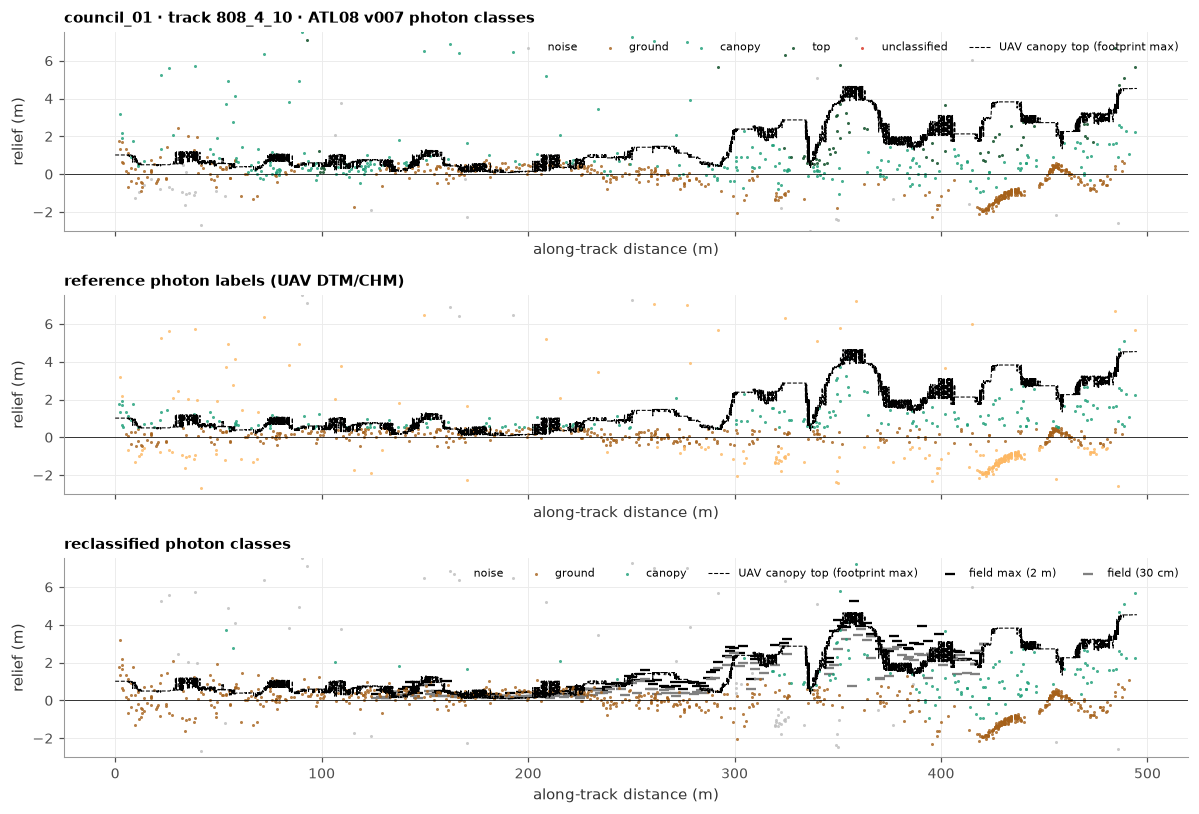

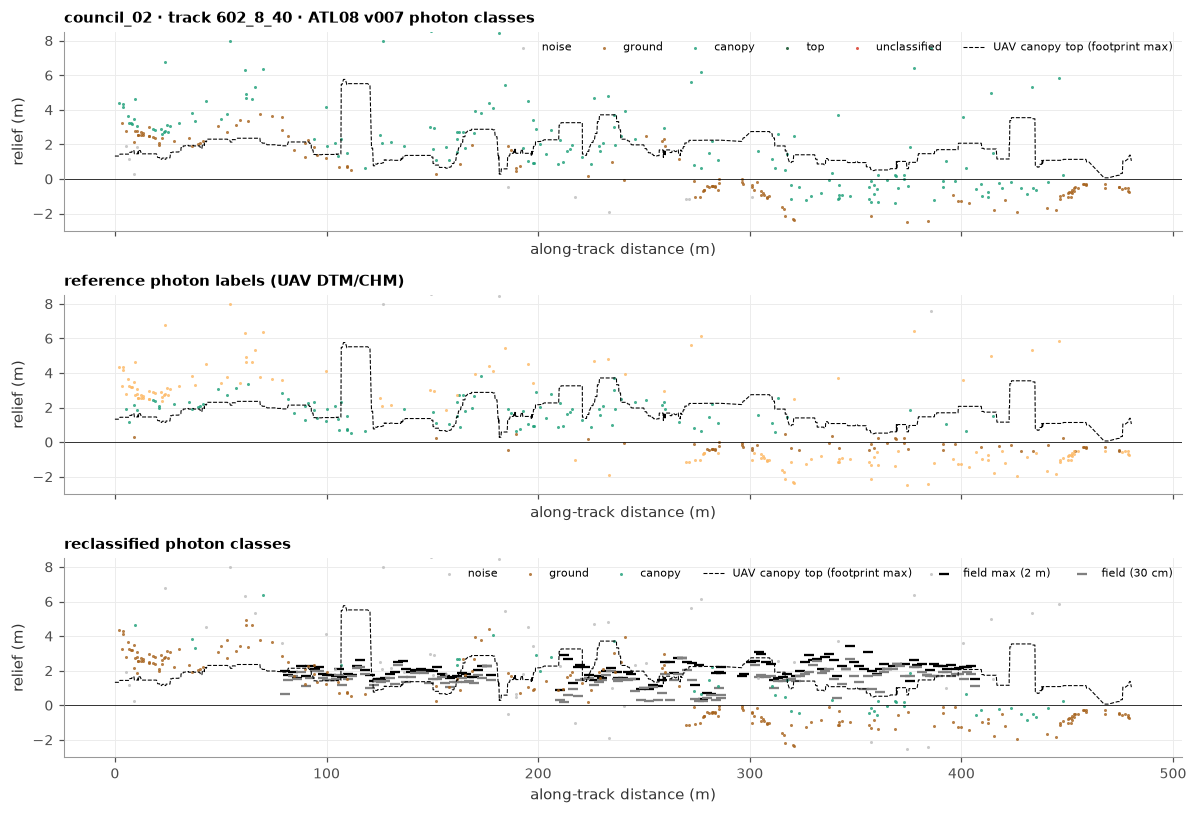

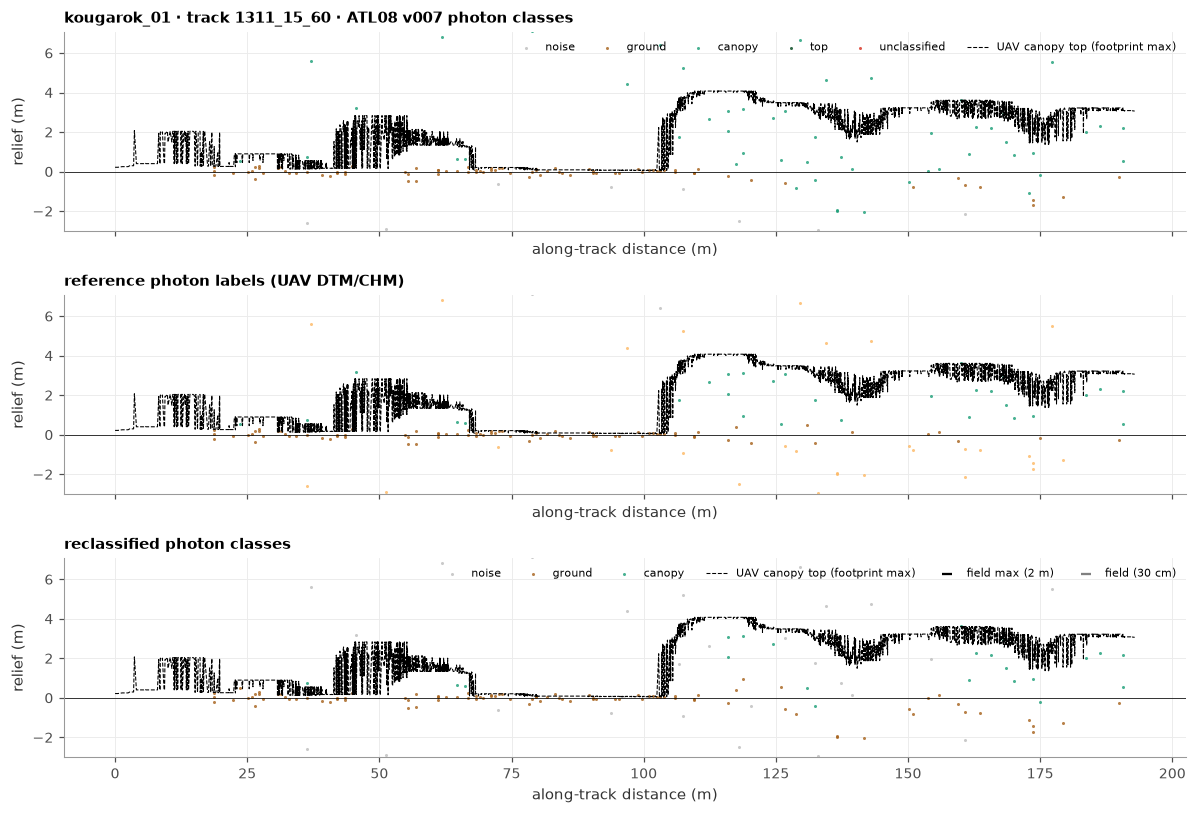

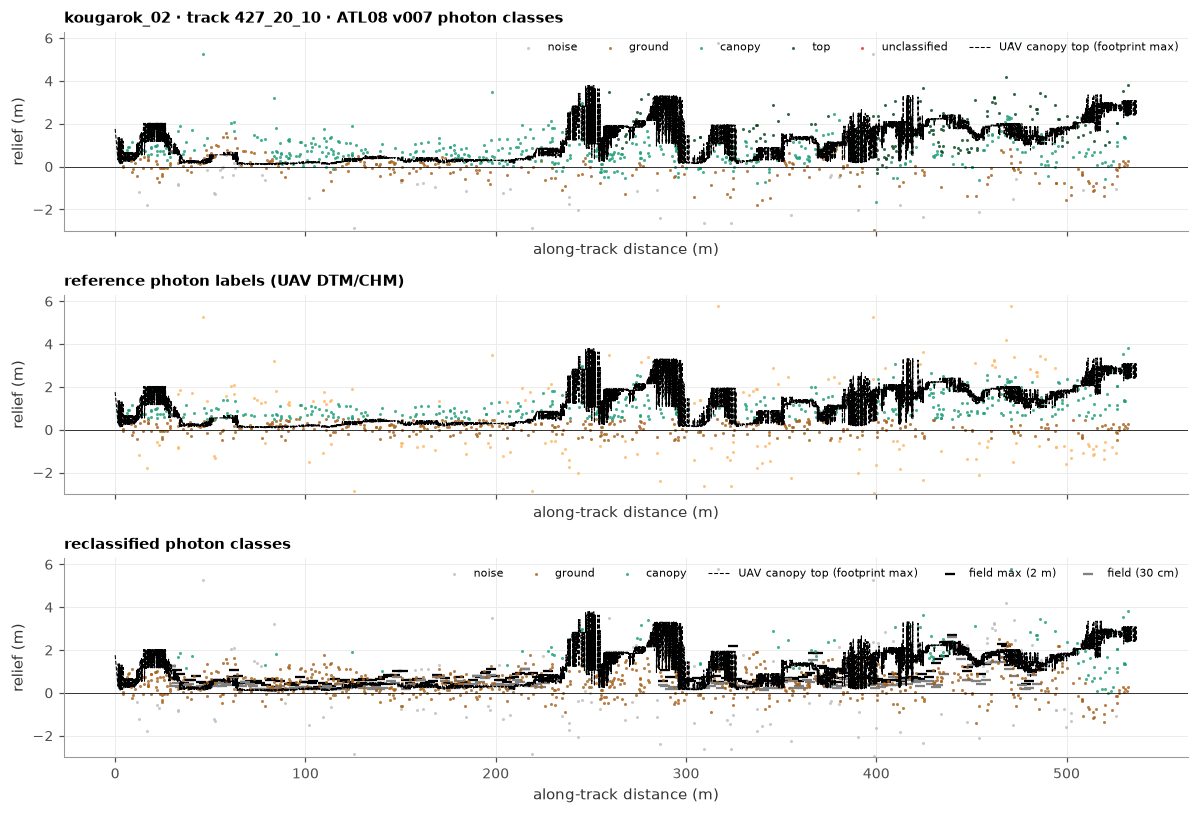

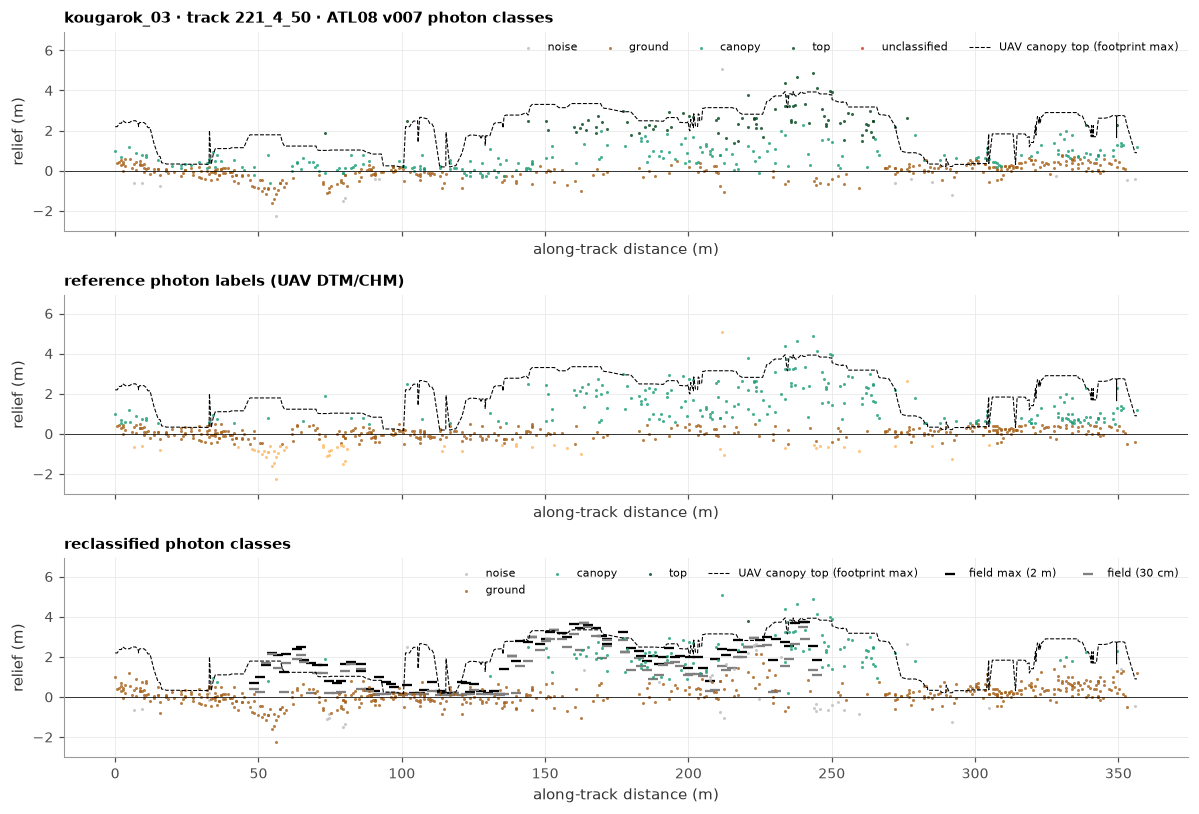

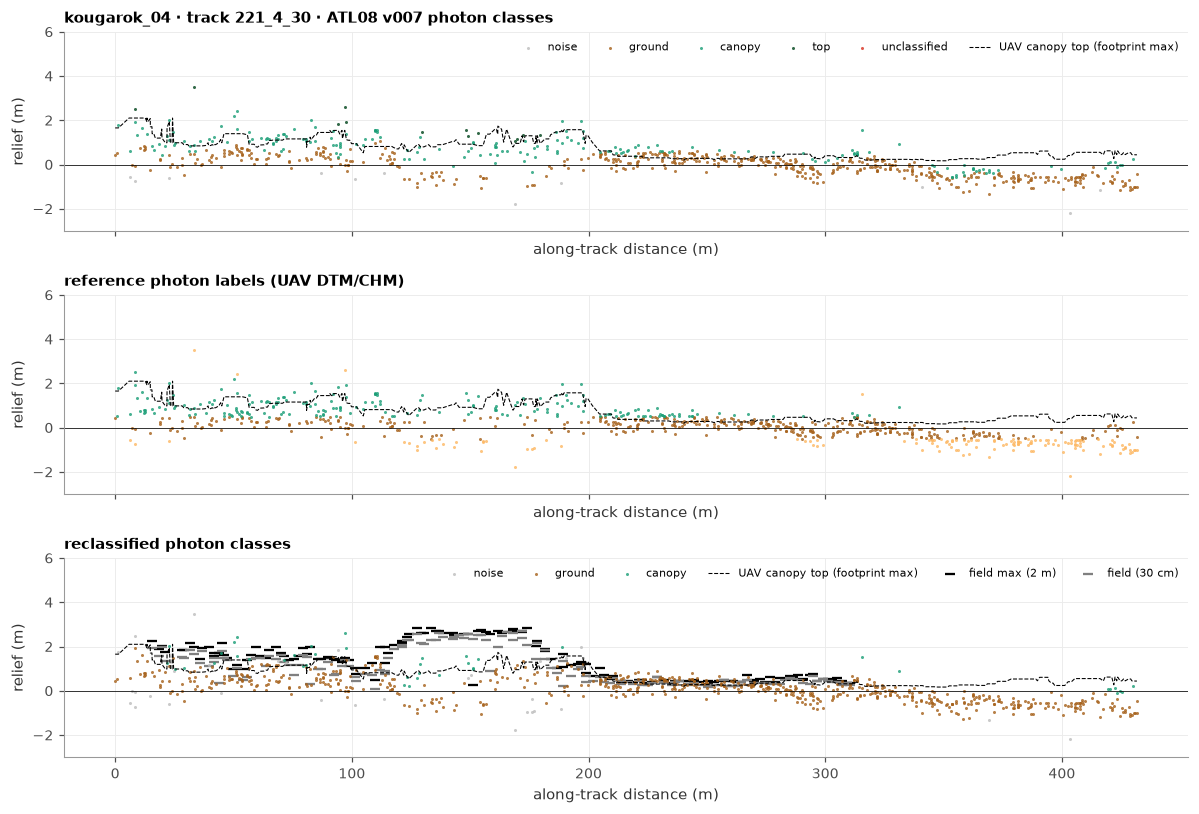

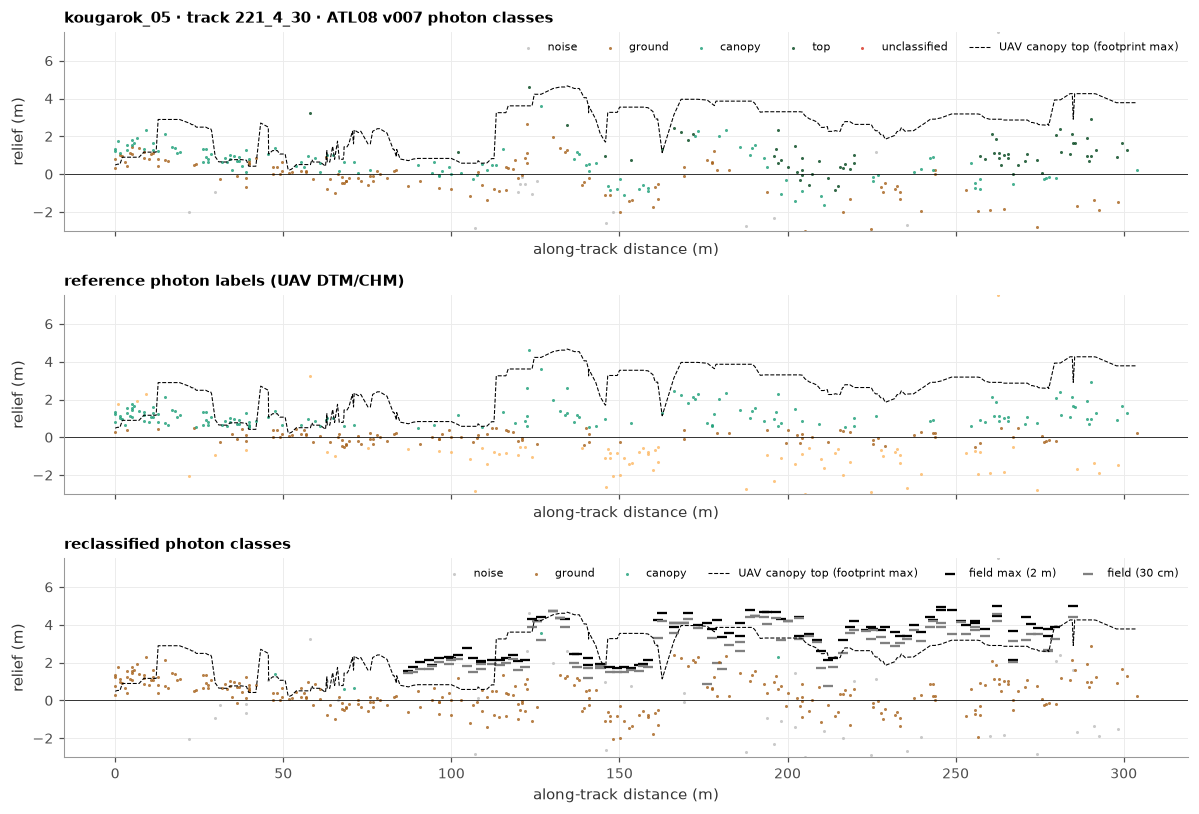

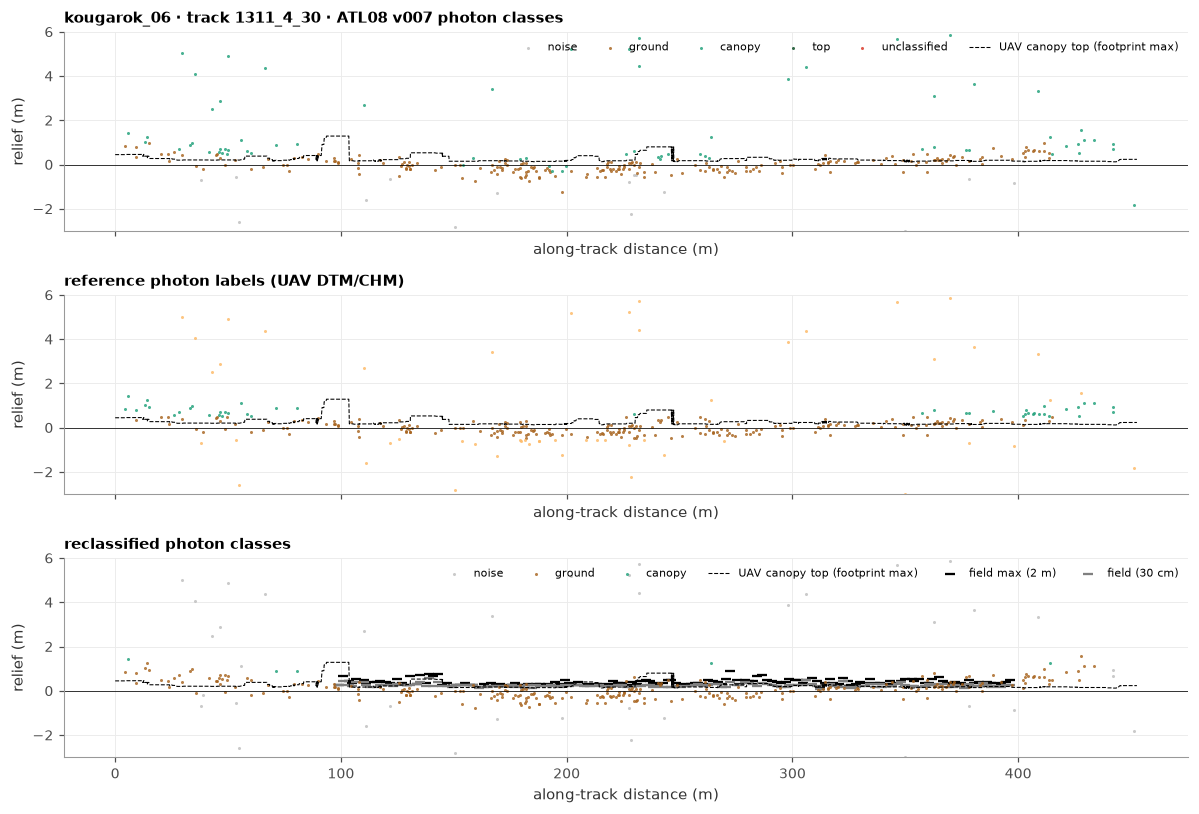

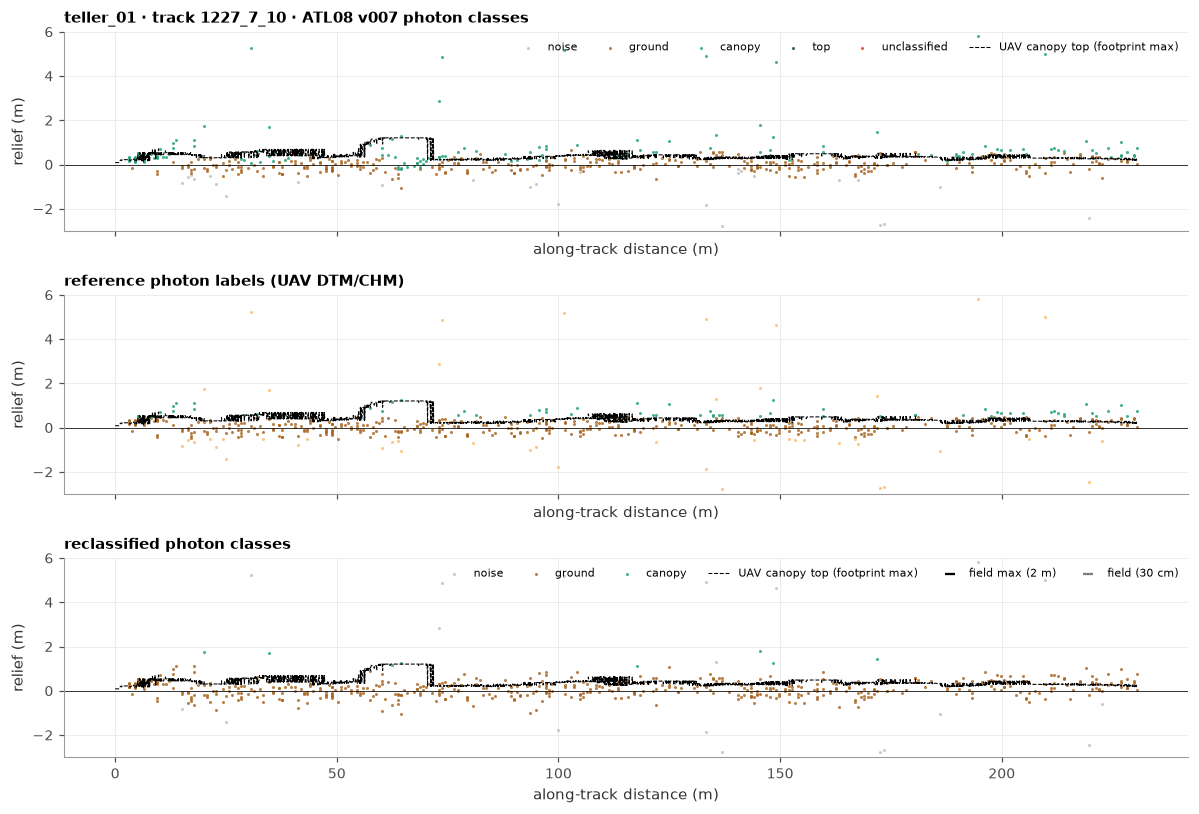

In [10]:
for site, ph in photons.items():
    inside = ph[ph.ref_label != "none"]
    if not len(inside): continue
    tid = inside.track_id.value_counts().index[0]
    p = ipl.track_profile(ph, tid)
    p = p[p.ref_label != "none"].copy()
    p["rel_ref"] = p["height"] - p["ref_ground"]
    p["ref_code"] = p["ref_label"].map({"noise": 0, "ground": 1, "canopy": 2, "buffer": 5})
    fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, sharey=True)
    val.plot_profile(axes[0], p, "atl08_class", val.ATL08_NAMES, "rel_ref", ref=False, title=f"{site} · track {tid} · {val.PHOTON_ATL08}")
    val.plot_profile(axes[1], p, "ref_code", {0: "noise", 1: "ground", 2: "canopy", 5: "buffer"}, "rel_ref", ref=False, title=val.PHOTON_REF + " (UAV DTM/CHM)")
    val.plot_profile(axes[2], p, "class_new", val.NEW_NAMES, "rel_ref", ref=False, title=val.PHOTON_NEW)
    x0 = p["x_atc"].min(); o = np.argsort(p["x_atc"].to_numpy())
    for ax in axes:
        ax.plot((p["x_atc"] - x0).to_numpy()[o], (p["ref_top"] - p["ref_ground"]).to_numpy()[o], c="k", lw=0.7, ls="--", label="UAV canopy top (footprint max)")
        ax.axhline(0, c="k", lw=0.5)
    f = field[field.site.str.lower() == site]
    if len(f):
        utm = p.estimate_utm_crs()
        pp = gpd.GeoDataFrame(p[["x_atc"]], geometry=gpd.points_from_xy(p.lon, p.lat), crs=4326).to_crs(utm)
        fj = gpd.sjoin_nearest(f.to_crs(utm), pp, max_distance=15)
        axes[2].scatter(fj.x_atc - x0, fj.height_cm_200cm / 100, marker="_", c="k", s=40, label="field max (2 m)")
        axes[2].scatter(fj.x_atc - x0, fj.height_cm_30cm / 100, marker="_", c="0.5", s=40, label="field (30 cm)")
    axes[0].set_ylim(-3, max(6, np.nanpercentile(p["ref_top"] - p["ref_ground"], 99) + 3))
    axes[0].legend(fontsize=7, ncol=6, loc="upper right"); axes[2].legend(fontsize=7, ncol=6, loc="upper right")
    fig.tight_layout(); fig.savefig(FIG / f"01_profile_{site}.png", dpi=150); plt.show()

## B · Photon classes against the reference photon labels

Photons inside the UAV models (buffer excluded). Rows: reference label; columns: the class each classification gave the
photon; row-normalised (each row sums to 1; counts in brackets). The key cell for short vegetation is **reference ground →
canopy**: those are the photons that create spurious heights.

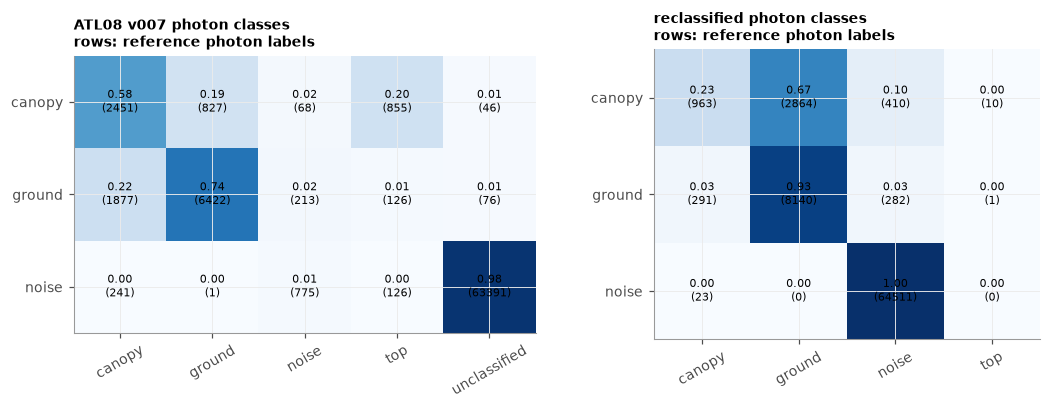

In [11]:
allph = pd.concat(photons.values(), ignore_index=True)
inside = allph[allph.ref_label.isin(["ground", "canopy", "noise"])]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (col, names, ttl) in zip(axes, [("atl08_class", val.ATL08_NAMES, val.PHOTON_ATL08), ("class_new", val.NEW_NAMES, val.PHOTON_NEW)]):
    t, tn = val.confusion(inside.ref_label, inside[col], names)
    ax.imshow(tn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(tn.shape[1]), tn.columns, rotation=30); ax.set_yticks(range(tn.shape[0]), tn.index)
    for i in range(tn.shape[0]):
        for j in range(tn.shape[1]):
            ax.text(j, i, f"{tn.iat[i, j]:.2f}\n({t.iat[i, j]})", ha="center", va="center", fontsize=7)
    ax.set_title(f"{ttl}\nrows: {val.PHOTON_REF}", fontsize=9, loc="left")
fig.tight_layout(); fig.savefig(FIG / "01_confusion_seward.png", dpi=150)

## C · 30 m segment heights against the UAV reference height

Each panel: one version of the 30 m segments (see Terms) against the reference height. Right: mean bias by reference-height
class. `spurious_veg_rate` = share of segments with reference height < 1 m where the version reports > 2 m.

How to read the reclassified panel: points at **0 m** are segments the short-vegetation guard set to 0 (`short_veg_flag`);
they are counted in the bias, so table D separates them.

n   bias   rmse  \
30 m version                  reference height class                        
ATL08 · PhoREAL (today)       0-0.5 m                 158.0  2.531  4.384   
                              0.5-1 m                  43.0  1.886  2.512   
                              1-2 m                    62.0  1.574  2.619   
                              2-5 m                    92.0  0.740  2.086   
                              all                     355.0  1.821  3.412   
                              spurious_veg_rate       201.0  0.468    NaN   
ATL08 · our binning (control) 0-0.5 m                 154.0  6.674  9.004   
                              0.5-1 m                  61.0  4.993  7.708   
                              1-2 m                    86.0  3.862  6.929   
                              2-5 m                   117.0  3.002  5.600   
                              all                     418.0  4.822  7.563   
                              spurious_veg_rate       215.0  0.614    NaN   
reclassified                  0-0.5 m                  93.0  1.110  5.999   
                              0.5-1 m                  41.0  0.596  3.260   
                              1-2 m                    52.0  1.404  7.194   
                              2-5 m                    77.0  0.744  4.479   
                              all                     263.0  0.981  5.522   
                              spurious_veg_rate       134.0  0.119    NaN   

                                                        mae  ref_mean  \
30 m version                  reference height class                    
ATL08 · PhoREAL (today)       0-0.5 m                 2.559     0.251   
                              0.5-1 m                 1.920     0.746   
                              1-2 m                   1.751     1.516   
                              2-5 m                   1.446     3.005   
                              all                     2.052     1.246   
                              spurious_veg_rate         NaN       NaN   
ATL08 · our binning (control) 0-0.5 m                 6.674     0.256   
                              0.5-1 m                 5.007     0.755   
                              1-2 m                   3.992     1.494   
                              2-5 m                   3.418     2.914   
                              all                     4.967     1.328   
                              spurious_veg_rate         NaN       NaN   
reclassified                  0-0.5 m                 1.558     0.260   
                              0.5-1 m                 1.455     0.760   
                              1-2 m                   3.121     1.519   
                              2-5 m                   2.241     2.900   
                              all                     2.051     1.360   
                              spurious_veg_rate         NaN       NaN   

                                                      est_mean  
30 m version                  reference height class            
ATL08 · PhoREAL (today)       0-0.5 m                    2.782  
                              0.5-1 m                    2.632  
                              1-2 m                      3.090  
                              2-5 m                      3.745  
                              all                        3.067  
                              spurious_veg_rate            NaN  
ATL08 · our binning (control) 0-0.5 m                    6.930  
                              0.5-1 m                    5.748  
                              1-2 m                      5.356  
                              2-5 m                      5.916  
                              all                        6.150  
                              spurious_veg_rate            NaN  
reclassified                  0-0.5 m                    1.370  
                              0.5-1 m                    1.356  
                

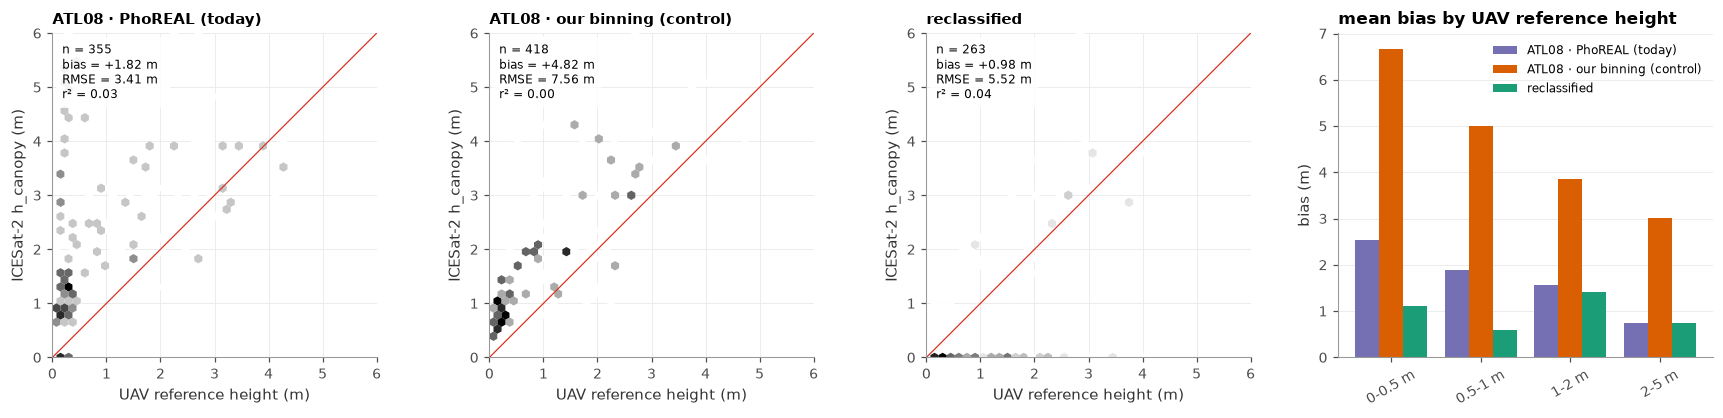

In [12]:
segs = pd.concat(segments.values(), ignore_index=True)
segs = segs[segs.als_n > 0]
edges = [0, 0.5, 1, 2, 5]
schemes = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08", val.LABEL_NEW: "h_canopy"}
tabs = {k: val.metrics_by_height_class(segs[c], segs["als_rh98"], edges, cfg["validation"]["spurious_veg"]) for k, c in schemes.items() if c in segs}
fig, axes = plt.subplots(1, len(tabs) + 1, figsize=(16, 3.9))
for ax, k in zip(axes, tabs):
    val.plot_scatter(ax, segs[schemes[k]], segs["als_rh98"], k, lim=6)
    ax.set_xlabel("UAV reference height (m)"); ax.set_ylabel("ICESat-2 h_canopy (m)")
val.plot_bias_by_class(tabs, "mean bias by UAV reference height", axes[-1])
fig.tight_layout(); fig.savefig(FIG / "01_segments_vs_uav.png", dpi=150)
pd.concat(tabs, names=["30 m version", "reference height class"]).round(3)

## D · What the short-vegetation guard does

Per reference-height class: the share of reclassified segments the guard set to 0 m, the median error of the reclassified
segments it kept, and, for comparison, the ATL08 · PhoREAL (today) segments. A guard that works sets most of the 0–0.5 m class to 0
and few of the taller classes.

In [13]:
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    g = segs[(segs.als_rh98 >= lo) & (segs.als_rh98 < hi)]
    if not len(g): continue
    kept = g[~g.short_veg_flag]
    rows.append({"reference height": f"{lo}-{hi} m", "segments": len(g),
                 "new: set to 0 by guard": round(g.short_veg_flag.mean(), 2),
                 "new: median |error| where kept (m)": round(float(np.median(np.abs(kept.h_canopy - kept.als_rh98))), 2) if len(kept) else np.nan,
                 "ATL08 · PhoREAL: median |error| (m)": round(float(np.nanmedian(np.abs(g.h_canopy_phoreal - g.als_rh98))), 2),
                 "ATL08 · PhoREAL: share > 2 m": round(float((g.h_canopy_phoreal > 2).mean()), 2),
                 "new: share > 2 m": round(float((g.h_canopy > 2).mean()), 2)})
f = segs[segs.short_veg_flag]
print("Why segments were set to 0 (share of guarded segments): fewer than 3 canopy photons", round((f.n_canopy < 3).mean(), 2),
      "| canopy RH98 < 0.6 m", round((f.h_canopy_raw < 0.6).mean(), 2), "| < 5 noise-corrected canopy photons", round((f.canopy_signal_photons < 5).mean(), 2))
print("Median shots per segment", segs.n_shots.median(), "| median canopy photons per segment", segs.n_canopy.median(),
      "| daytime share", round((segs.solar_elevation > 0).mean(), 2))
pd.DataFrame(rows)

Why segments were set to 0 (share of guarded segments): fewer than 3 canopy photons 0.91 | canopy RH98 < 0.6 m 0.0 | < 5 noise-corrected canopy photons 0.99
Median shots per segment 43.0 | median canopy photons per segment 1.0 | daytime share 0.83


,reference height,segments,new: set to 0 by guard,new: median |error| where kept (m),ATL08 · PhoREAL: median |error| (m),ATL08 · PhoREAL: share > 2 m,new: share > 2 m
0,0-0.5 m,199,0.40,NaN,1.34,0.35,0.04
1,0.5-1 m,69,0.35,NaN,1.46,0.36,0.13
2,1-2 m,95,0.32,NaN,1.32,0.43,0.17
3,2-5 m,131,0.12,NaN,0.91,0.59,0.43


## E · Segments that contain field points

Same three versions against the tallest field height within 2 m of the points inside each segment.

,site,track_id,field_n,field_max_200,field_mean_30,als_rh98,h_canopy_phoreal,h_canopy_atl08,h_canopy
99,council_01,808_4_10,4.0,0.56,0.16,0.60,NaN,10.55,0.0
100,council_01,808_4_10,15.0,1.01,0.32,0.75,NaN,12.77,0.0
101,council_01,808_4_10,15.0,0.50,0.18,0.11,NaN,11.07,0.0
102,council_01,808_4_10,15.0,0.69,0.22,0.31,NaN,11.02,0.0
103,council_01,808_4_10,15.0,1.30,0.50,0.78,NaN,10.71,0.0
...,...,...,...,...,...,...,...,...,...
1968,teller_01,1227_20_10,15.0,1.35,0.80,0.37,1.41,1.15,0.0
1969,teller_01,1227_20_10,15.0,1.18,0.51,0.27,1.49,1.47,0.0
1970,teller_01,1227_20_10,14.0,1.00,0.40,0.28,1.63,1.47,0.0
1971,teller_01,1227_20_10,14.0,1.23,0.69,0.27,1.35,0.84,0.0


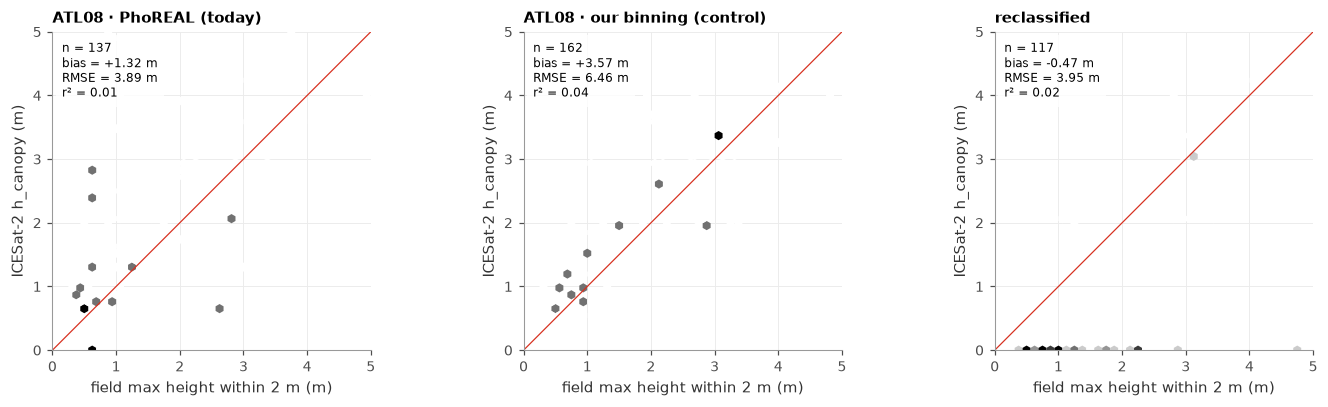

In [14]:
fs = segs[segs.field_n > 0]
if len(fs):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, k in zip(axes, tabs):
        val.plot_scatter(ax, fs[schemes[k]], fs["field_max_200"], k, lim=5)
        ax.set_xlabel("field max height within 2 m (m)"); ax.set_ylabel("ICESat-2 h_canopy (m)")
    fig.tight_layout(); fig.savefig(FIG / "01_segments_vs_field.png", dpi=150)
fs[["site", "track_id", "field_n", "field_max_200", "field_mean_30", "als_rh98"] + [c for c in schemes.values() if c in fs]].round(2)

## Results (final, config v0.6, 18 October 2026)

Same segments for every version (notebook 11; 203 segments with a drone reference, 97 with field points):
- **Spurious vegetation** (drone < 1 m, ICESat-2 > 2 m): ATL08 · PhoREAL (today) **39 %** → v0.2 20 % → v0.4 9 % → **v0.6 7 %**.
- **Mean bias vs the drone CHM:** today **+1.5 m** → v0.6 **0.0 m** (0–1 m class +1.8 → 0.0 m; 1–2 m +1.6 → +0.6 m).
- **One outlier:** a single v0.6 segment is reported at **38 m** over < 2 m tundra. It alone makes the v0.6 RMSE (2.9 m)
  larger than today's (2.4 m); without it v0.6 RMSE is 1.2 m against today's 2.3 m. A plausibility cap on heights over tundra
  is the guard for production.
- **Field heights (tallest within 2 m of each point):** spurious vegetation 14 → 7 %; bias +0.7 → −0.6 m. v0.6 reads below the
  field heights in the 1–5 m classes (−1.0 to −1.3 m), as expected for a 98th percentile of a 30 m segment against the tallest
  shrub near each point.
- About half of the segments get a height (today 72 %, v0.6 53 %); acceptable for the multi-year biomass models.

### Earlier: first run (config v0.1, 14 October 2026)

- **Spurious vegetation** (UAV < 1 m, ICESat-2 > 2 m): ATL08 · PhoREAL (today) about 50 %; reclassified photons → our 30 m about 12 %.
- **Where the reclassified segments report a height**, their median error is lower than the ATL08 · PhoREAL (today) in every height
  class (e.g. 0.54 vs 0.98 m for 2–5 m vegetation).
- **But the short-vegetation guard is too aggressive:** it sets about 40 % of segments with 0.5–5 m vegetation to 0 m, all because
  of the "≥ 5 noise-corrected canopy photons" rule. These transects are photon-starved (mostly daytime, about 5 canopy photons per
  segment). Planned for config v0.2, after the G-LiHT results: a separate `low_signal` flag with `h_canopy = NaN` (not 0), and the
  photon threshold tuned on Seward + G-LiHT (notebook 03).
- **ATL08 · our binning (control)** is much worse than the ATL08 · PhoREAL (today) from the same ATL08 classes: PhoREAL's top-of-canopy
  handling removes scattered high photons that our binning keeps. The comparison that matters is ATL08 · PhoREAL vs new.
- Kougarok 03–05 returned far fewer photons than the other transects; to be checked.